In [1]:
import os
os.chdir("..")
print(f"Current directory: {os.getcwd()}")

Current directory: c:\Users\przem\Desktop\DTU\MACE


In [2]:
import cuequivariance as cue
import cuequivariance_torch as cuet
from modules.blocks import InteractionBlock

c:\Users\przem\Desktop\DTU\MACE\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
node_attrs_irreps = cue.Irreps("O3", "4x0e")
node_feats_irreps = cue.Irreps("O3", "16x0e + 4x1o + 2x2o")
edge_attrs_irreps = cue.Irreps("O3", "1x0e + 1x1o + 1x2e + 1x3o")
edge_feats_irreps =cue.Irreps("O3", "16x0e")
hidden_irreps = cue.Irreps("O3", "32x0e + 32x1o + 32x2o + 32x3o")
mid_irreps = edge_attrs_irreps
target_irreps =  cue.Irreps("O3", "1x0e")

interaction = InteractionBlock(node_attrs_irreps, node_feats_irreps, edge_attrs_irreps,
edge_feats_irreps, hidden_irreps, mid_irreps, target_irreps)

c:\Users\przem\Desktop\DTU\MACE\.venv\Lib\site-packages\cuequivariance\group_theory\irreps_array\misc_ui.py:25: UserWarning: layout is not specified, defaulting to cue.mul_ir. This is the layout used in the e3nn library. We use it as the default layout for compatibility with e3nn. However, the cue.ir_mul layout is faster and more memory efficient. Please specify the layout explicitly to avoid this warning.
  warnings.warn(
c:\Users\przem\Desktop\DTU\MACE\.venv\Lib\site-packages\cuequivariance\group_theory\irreps_array\misc_ui.py:25: UserWarning: layout is not specified, defaulting to cue.mul_ir. This is the layout used in the e3nn library. We use it as the default layout for compatibility with e3nn. However, the cue.ir_mul layout is faster and more memory efficient. Please specify the layout explicitly to avoid this warning.
  warnings.warn(
c:\Users\przem\Desktop\DTU\MACE\.venv\Lib\site-packages\cuequivariance\group_theory\irreps_array\misc_ui.py:25: UserWarning: layout is not specifi

In [4]:
import torch
from modules.utils import neighbour_sum

num_nodes = 8
num_edges = 20

# Feature dimensions:
# node_attrs_irreps: 4x0e -> 4
# node_feats_irreps: 16x0e + 4x1o + 2x2o -> 16 + 12 + 10 = 38
# edge_feats_irreps: 16x0e -> 16
# edge_attrs_irreps: 0e + 1o + 2o + 3o -> 1 + 3 + 5 + 7 = 16

node_attrs = torch.randn(num_nodes, 4)
node_feats = torch.randn(num_nodes, 38)
edge_feats = torch.randn(num_edges, 16)
edge_attrs = torch.randn(num_edges, 16)

# Directed edge list: source and destination node indices
edge_index = torch.randint(
    0, num_nodes, (2, num_edges), dtype=torch.long
)


"""
print(node_feats.shape)
node_feats = interaction.linear_h(node_feats)
print(node_feats.shape)
tp_weights = interaction.tp_weights(edge_feats)
print(tp_weights.shape)
message = interaction.tp(edge_attrs, node_feats[edge_index[0]], tp_weights)
print(message.shape)
mid_irreps = interaction.tp.irreps_out
message = neighbour_sum(message, edge_index, node_feats.shape[0])
print(message.shape)
message = interaction.linear_out(message)
"""
output = interaction(
    #node_attrs,
    node_feats,
    edge_attrs,
    edge_feats,
    edge_index,
)

print(output.shape)

torch.Size([8, 1])



## Loading the example dataset


In [5]:
from torch_geometric.datasets import QM9
# this only downloads the dataset
dataset = QM9("data/")
print(len(dataset))  # 130831

molecule = dataset[0]
print(molecule)

130831
Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5])


In [6]:
from torch_geometric.loader import DataLoader

train_loader = DataLoader(
    dataset[:100_000],
    batch_size=32,
    shuffle=True,
)

for batch in train_loader:
    # num_atoms and num_edges are counted in the whole batch
    print(batch.z.shape) # [num_atoms]
    print(batch.pos.shape) # [num_atoms, 3]
    print(batch.edge_index.shape) # [2, num_edges]
    print(batch.batch.shape) # [num_atoms]

    # Example: target 7 = U0, internal energy at 0 K
    target = batch.y[:, 7]
    break

torch.Size([544])
torch.Size([544, 3])
torch.Size([2, 1122])
torch.Size([544])



## Checking the radial embedding and spherical harmonics

In [22]:
from modules.utils import get_vectors_and_lengths
from modules.radial import BesselBasis, PolynomialCutoff
from cuequivariance_torch import SphericalHarmonics

bessels = BesselBasis(5)
cutoff = PolynomialCutoff(5,2)
harmonics = SphericalHarmonics([0,1,2])

for batch in train_loader:
    vecs, lens = get_vectors_and_lengths(batch.pos, batch.edge_index)
    print(batch.edge_index.shape)
    print(vecs.shape)
    print(lens.shape)

    bessel = bessels(lens)
    print(bessel.shape)
    edge_feats = cutoff(bessel)
    print(edge_feats.shape)
    edge_attrs = harmonics(vecs)
    print(edge_attrs.shape)
    break

torch.Size([2, 1280])
torch.Size([1280, 3])
torch.Size([1280])
torch.Size([1280, 16])
torch.Size([1280, 16])
torch.Size([1280, 9])


c:\Users\przem\Desktop\DTU\MACE\.venv\Lib\site-packages\cuequivariance_torch\primitives\segmented_polynomial.py:183: UserWarning: cuequivariance_ops_torch is not available. Falling back to naive implementation.
  warnings.warn(


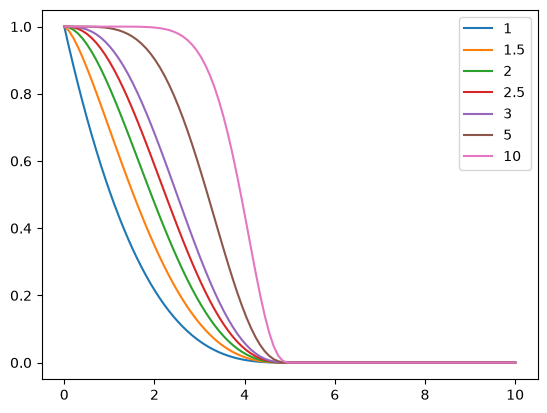

In [18]:
# polynomial cutoff viz
import matplotlib.pyplot as plt

x = torch.linspace(0,10,100)
for p in [1,1.5,2,2.5,3,5,10]:
    y = PolynomialCutoff(5,p)(x)
    plt.plot(x,y,label=p)
plt.legend()
plt.show()


## Check if the blocks work


In [ ]:
from modules.blocks import InteractionBlock, SymmetricContractionBlock

